# Độ nhạy của kết quả theo cách chia pha của $g(t)$

Notebook này là phần **khuyến nghị** đi kèm `penguin_o2_transfer_model.ipynb`. Mô hình chính giữ nguyên cách chia của ghi chú: ba đoạn bằng nhau theo $x=t_{min}/T_d$ (mốc $1/3$ và $2/3$). Notebook trả lời ba câu hỏi:

| Câu hỏi | Mục |
|---|---|
| Kết luận "Type B có $g$ lớn hơn Type A" có phụ thuộc vào việc chia $1/3$–$2/3$ hay không? Các cách chia khác (hai nửa, bốn phần, theo độ sâu, mốc cố định theo giây) cho kết luận gì? | 7 |
| $g_1,g_2,g_3$ có đúng là "pha xuống, đáy, lên" của cú lặn không? Nếu muốn gọi tên theo sinh lý thì làm thế nào? | 3, 8 |
| Nên chọn cách chia bằng tiêu chí nào? Sai số trong mẫu có phân biệt được các cách chia không? Ngoài mẫu thì sao? | 5, 6, 9 |

**Nguyên tắc đọc kết quả**
- Sai số **trong mẫu** (tham số và sai số tính trên cùng dữ liệu) luôn giảm khi thêm đoạn; không dùng nó để chọn cách chia.
- Sai số **ngoài mẫu** là leave-one-bird-out: $g_k$ chung theo nhóm ước lượng từ các chim khác, $r$ lồng nhau, $S_{init}$ lấy từ $S_v$ trước lặn.
- Mọi khoảng tin cậy dùng bootstrap **theo cá thể** (lấy mẫu chim, rồi lấy mẫu cú lặn trong chim), vì các cú lặn của cùng một chim không độc lập.

**Cần chạy trước:** `penguin_o2_transfer_model.ipynb` (xuất `../data/model_params.json` chứa $r$, $\tau_a$ và $r$ lồng nhau).

## 1. Cấu hình và tham số lấy từ notebook chính

In [14]:
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import lfilter
from scipy.optimize import lsq_linear
from scipy.stats import wilcoxon

DIR, RES_DIR = "../data", "../results/split_sensitivity"
os.makedirs(RES_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# --- hằng số mô hình (giống notebook chính) ---
P50, N_HILL = 28.2, 2.93
S_REST, S_DIVE0, K_EXP = 0.97, 0.987, 5
DT_MIN = 0.05
G_MAX = 0.9
MIN_ROWS_DIVE, MIN_PER_THIRD = 12, 2     # cùng điều kiện chọn cú lặn như notebook chính
TD_MAX_ART = 11.7
PRE_SEARCH_MIN = 1.0                     # S_v trước lặn: mẫu cuối trong 1 phút trước khi bắt đầu lặn
AV_FACTOR = 18.0 * 1.34                  # g -> mL O2/dL
N_BOOT_BIRD, N_PERM, SEED = 2000, 10000, 42
GROUPS = ["Type A venous", "Type B venous"]
COL = {"Type A venous": "tab:orange", "Type B venous": "tab:green"}

# --- r, tau_a, r lồng nhau: đọc từ notebook chính ---
try:
    with open(f"{DIR}/model_params.json", encoding="utf-8") as fh: prm = json.load(fh)
    TAU_A = float(prm["estimated"]["tau_a_min"]); R = float(prm["estimated"]["r_min"])
    R_NESTED = {k: float(v) for k, v in prm["estimated"].get("r_nested_by_held_out_bird", {}).items()}
    print(f"Đọc từ model_params.json: tau_a = {TAU_A:.3f}, r = {R:.3f}, r lồng nhau cho {len(R_NESTED)} chim")
except FileNotFoundError:
    TAU_A, R, R_NESTED = 1.578, 0.764, {}
    warnings.warn("Không thấy model_params.json: dùng giá trị mặc định tau_a=1.578, r=0.764 và r toàn bộ cho kiểm định ngoài mẫu. Hãy chạy notebook chính trước.")

C:\Users\PC\AppData\Local\Temp\ipykernel_20012\3581569381.py:35: UserWarning: Không thấy model_params.json: dùng giá trị mặc định tau_a=1.578, r=0.764 và r toàn bộ cho kiểm định ngoài mẫu. Hãy chạy notebook chính trước.
  warnings.warn("Không thấy model_params.json: dùng giá trị mặc định tau_a=1.578, r=0.764 và r toàn bộ cho kiểm định ngoài mẫu. Hãy chạy notebook chính trước.")


## 2. Dữ liệu và tập cú lặn

Bước này dựng bảng cú lặn tĩnh mạch và chọn đúng tập cú lặn mà notebook chính dùng cho phương án "chỉ lặn" (cùng điều kiện số điểm), để các so sánh giữa các cách chia diễn ra **trên cùng một tập cú lặn**. Với mỗi cú lặn có: chuỗi $S_v$ và độ sâu trong $[0,T_d]$, và $S_v$ ngay trước lặn (dùng làm điều kiện đầu cho đánh giá ngoài mẫu).

In [15]:
ts = pd.read_csv(f"{DIR}/penguin_merged.csv")
assert np.abs(ts["PO2"].pow(N_HILL) / (P50**N_HILL + ts["PO2"].pow(N_HILL)) - ts["Hb"]).max() < 1e-3, "Cột Hb không khớp Hill"
ts["t_start"] = ts["t"] - ts["t_in_dive_s"]

inside = ts[ts["dive_id"].notna() & ~ts["excluded_dive"]]
dv = inside.groupby("dive_id").agg(bird=("bird", "first"), site=("site", "first"), group=("group", "first"),
                                   t_start=("t_start", "first"), Td=("dive_dur_min", "first"), z_max=("depth_m", "max"))
dv["t_end"] = dv["t_start"] + 60.0 * dv["Td"]
ven = dv[dv["site"] == "venous"].copy()
ven["extrapolated"] = ven["Td"] > TD_MAX_ART

BY_BS = {k: g.sort_values("t") for k, g in ts.groupby(["bird", "site"])}      # tra cứu nhanh theo (chim, site)

def dive_rows(did):
    d = ven.loc[did]; g = BY_BS[(d["bird"], d["site"])]
    g = g[(g["t"] >= d["t_start"]) & (g["t"] <= d["t_end"])]
    return pd.DataFrame({"t_min": (g["t"].values - d["t_start"]) / 60.0, "Hb": g["Hb"].values, "depth": g["depth_m"].values})

def pre_dive_S(did):
    d = ven.loc[did]; g = BY_BS[(d["bird"], d["site"])]
    p = g[(g["t"] >= d["t_start"] - 60 * PRE_SEARCH_MIN) & (g["t"] < d["t_start"]) & g["dive_id"].isna() & ~g["unlisted_dive"]]
    return float(p["Hb"].iloc[-1]) if len(p) else np.nan

SER, ELIG = {}, []
for did in ven.index:
    s = dive_rows(did); Td = ven.at[did, "Td"]
    n3 = [((s["t_min"] >= lo) & (s["t_min"] < hi)).sum() for lo, hi in [(0, Td/3), (Td/3, 2*Td/3)]] + [((s["t_min"] >= 2*Td/3) & (s["t_min"] <= Td)).sum()]
    if len(s) >= MIN_ROWS_DIVE and min(n3) >= MIN_PER_THIRD:
        SER[did] = s.sort_values("t_min").reset_index(drop=True); ELIG.append(did)
D = ven.loc[ELIG].copy()
D["S_pre"] = [pre_dive_S(i) for i in D.index]
D["n_rows"] = [len(SER[i]) for i in D.index]
print(f"Cú lặn tĩnh mạch: {len(ven)}; đủ điều kiện (≥{MIN_ROWS_DIVE} điểm, ≥{MIN_PER_THIRD} điểm mỗi phần ba): {len(D)}")
display(D.groupby("group").agg(so_lan_lan=("Td", "size"), so_chim=("bird", "nunique"), Td_trung_vi=("Td", "median"),
                               n_diem_trung_vi=("n_rows", "median"), co_S_truoc_lan=("S_pre", lambda s: int(s.notna().sum()))).round(2))

Cú lặn tĩnh mạch: 93; đủ điều kiện (≥12 điểm, ≥2 điểm mỗi phần ba): 79


,so_lan_lan,so_chim,Td_trung_vi,n_diem_trung_vi,co_S_truoc_lan
group,,,,,
Type A venous,18,5,4.38,23.5,18
Type B venous,61,8,9.35,40.0,50


## 3. Các cách chia pha

Mỗi cách chia là một danh sách mốc thời gian (phút, tính từ lúc bắt đầu lặn) cắt $[0,T_d]$ thành $K$ đoạn, mỗi đoạn một $g_k$. Các cách chia được so sánh:

| Tên | $K$ | Mốc | Vai trò |
|---|---|---|---|
| `thirds` | 3 | $T_d/3,\ 2T_d/3$ | **Chính** (ghi chú) |
| `halves` | 2 | $T_d/2$ | Độ nhạy |
| `quarters` | 4 | $T_d/4,\ T_d/2,\ 3T_d/4$ | Độ nhạy |
| `depth70/80/90` | 3 | thời điểm đầu tiên và cuối cùng độ sâu $\ge$ 70/80/90% $z_{max}$ | Phụ, gọi tên sinh lý "xuống / đáy / lên" |
| `fixed_ends` | 3 | 1 phút đầu và 1 phút cuối (mốc cố định theo giây) | Độ nhạy |
| `constant` | 1 | không có mốc | Đường chuẩn tiết kiệm nhất |

Với `depthXX`, nếu mốc suy biến (độ sâu đạt ngưỡng ngay từ đầu hoặc đến cuối cú lặn) thì quay về mốc `thirds` và cú lặn đó được đếm là "dự phòng".

In [16]:
def Sa_template(t_min, Td, tau_a=TAU_A):
    t_min = np.asarray(t_min, float); dS = np.clip(-0.141 + 0.183 * np.log(Td), 0.0, 0.6)
    x = np.clip(t_min / Td, 0, 1); s_end = S_DIVE0 - dS
    dive = S_DIVE0 - dS * x**K_EXP
    post = S_REST - (S_REST - s_end) * np.exp(-np.maximum(t_min - Td, 0.0) / tau_a)
    return np.where(t_min < 0, S_REST, np.where(t_min <= Td, dive, post))

def b_thirds(Td, s):   return [Td / 3, 2 * Td / 3]
def b_halves(Td, s):   return [Td / 2]
def b_quarters(Td, s): return [Td / 4, Td / 2, 3 * Td / 4]
def b_const(Td, s):    return []
def b_fixed(Td, s):    return [min(1.0, Td / 3), max(Td - 1.0, 2 * Td / 3)]
def b_depth(frac):
    def f(Td, s):
        z = s["depth"].to_numpy(float); t = s["t_min"].to_numpy(float)
        m = np.isfinite(z) & (z >= frac * np.nanmax(z))
        if m.sum() < 2: return None
        b = [float(t[m][0]), float(t[m][-1])]
        return b if (0 < b[0] < b[1] < Td) else None      # suy biến -> None
    return f

SCHEMES = {
    "constant":    (b_const,    ["cả cú lặn"]),
    "halves":      (b_halves,   ["nửa đầu", "nửa sau"]),
    "thirds":      (b_thirds,   ["đầu (0–1/3)", "giữa (1/3–2/3)", "cuối (2/3–1)"]),
    "quarters":    (b_quarters, ["Q1", "Q2", "Q3", "Q4"]),
    "depth70":     (b_depth(0.70), ["xuống", "đáy", "lên"]),
    "depth80":     (b_depth(0.80), ["xuống", "đáy", "lên"]),
    "depth90":     (b_depth(0.90), ["xuống", "đáy", "lên"]),
    "fixed_ends":  (b_fixed,    ["1 phút đầu", "giữa", "1 phút cuối"]),
}
MAIN = "thirds"

BOUNDS, FALLBACK = {}, {}
for sc, (fn, labs) in SCHEMES.items():
    for did in D.index:
        b = fn(D.at[did, "Td"], SER[did]); fb = b is None
        BOUNDS[(sc, did)] = b_thirds(D.at[did, "Td"], None) if fb else b; FALLBACK[(sc, did)] = fb
FB = pd.Series(FALLBACK).unstack(0).groupby(D["group"]).sum()
print("Số cú lặn phải dự phòng về mốc 'thirds' (mốc theo độ sâu suy biến):"); display(FB[[c for c in FB.columns if c.startswith("depth")]])

Số cú lặn phải dự phòng về mốc 'thirds' (mốc theo độ sâu suy biến):


,depth70,depth80,depth90
group,,,
Type A venous,0,0,3
Type B venous,0,0,1


### 3.1 Cách chia 1/3–2/3 có trùng các pha thật của cú lặn không?

Bước này đo mức trùng giữa ba phần ba theo thời gian và ba pha theo độ sâu (`depth80`: xuống / đáy / lên). Mỗi hàng của ma trận là một phần ba; mỗi ô là **tỉ lệ điểm đo** của phần ba đó nằm trong từng pha theo độ sâu (trung bình qua các cú lặn). Nếu $g_1,g_2,g_3$ đúng là "xuống, đáy, lên" thì ma trận phải gần ma trận đơn vị.

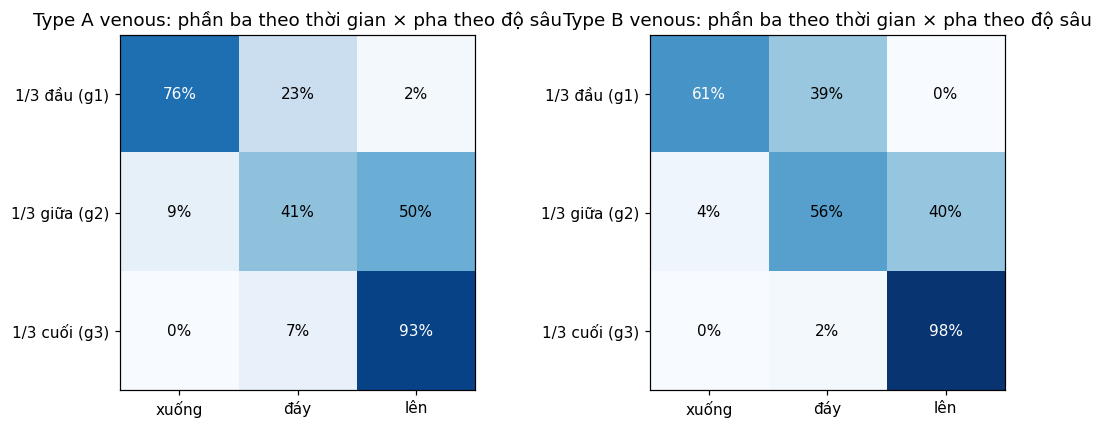

Độ trùng trung bình (trung bình đường chéo): {'Type A venous': 0.7, 'Type B venous': 0.72} (1 = trùng hoàn toàn; ngẫu nhiên ≈ 0,33)


In [17]:
def phase_idx(t, bounds): return np.searchsorted(np.asarray(bounds, float), np.round(np.asarray(t, float), 9), side="right")

XT = {}
for grp in GROUPS:
    mats = []
    for did in D.index[(D["group"] == grp)]:
        if FALLBACK[("depth80", did)]: continue
        t = SER[did]["t_min"].values; pt = phase_idx(t, BOUNDS[("thirds", did)]); pdp = phase_idx(t, BOUNDS[("depth80", did)])
        M = np.full((3, 3), np.nan)
        for i in range(3):
            if (pt == i).any(): M[i] = [np.mean(pdp[pt == i] == j) for j in range(3)]
        mats.append(M)
    XT[grp] = np.nanmean(np.stack(mats), axis=0)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a_, grp in zip(ax, GROUPS):
    a_.imshow(XT[grp], vmin=0, vmax=1, cmap="Blues")
    for i in range(3):
        for j in range(3): a_.text(j, i, f"{100*XT[grp][i,j]:.0f}%", ha="center", va="center", color="k" if XT[grp][i, j] < 0.6 else "w")
    a_.set_xticks(range(3)); a_.set_xticklabels(["xuống", "đáy", "lên"]); a_.set_yticks(range(3)); a_.set_yticklabels(["1/3 đầu (g1)", "1/3 giữa (g2)", "1/3 cuối (g3)"])
    a_.set_title(f"{grp}: phần ba theo thời gian × pha theo độ sâu"); a_.grid(False)
plt.tight_layout(); plt.savefig(f"{RES_DIR}/fig_thirds_vs_depth_phases.png", dpi=140); plt.show()
print("Độ trùng trung bình (trung bình đường chéo):", {g: round(float(np.trace(XT[g]) / 3), 2) for g in GROUPS}, "(1 = trùng hoàn toàn; ngẫu nhiên ≈ 0,33)")

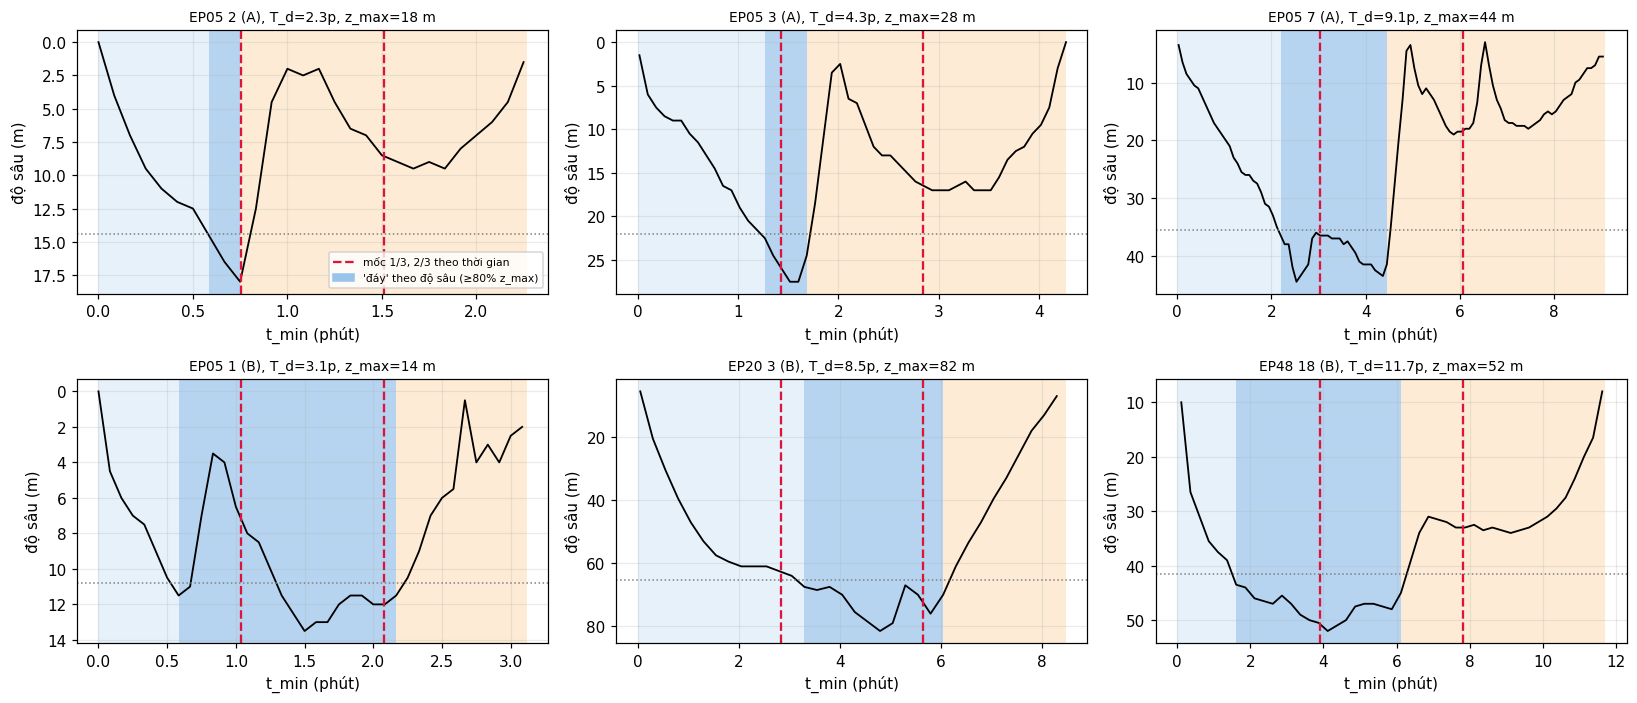

In [18]:
def pick_spread(ids, k):
    ids = sorted(ids, key=lambda i: D.at[i, "Td"]); return [ids[j] for j in np.unique(np.linspace(0, len(ids) - 1, min(k, len(ids))).astype(int))]
ex = pick_spread(list(D.index[D["group"] == GROUPS[0]]), 3) + pick_spread(list(D.index[(D["group"] == GROUPS[1]) & ~D["extrapolated"]]), 3)
fig, axs = plt.subplots(2, 3, figsize=(15, 6.5))
for a, did in zip(axs.ravel(), ex):
    s = SER[did]; Td = D.at[did, "Td"]; bd = BOUNDS[("depth80", did)]
    for (lo, hi), c in zip([(0, bd[0]), (bd[0], bd[1]), (bd[1], Td)], ["#dcecf9", "#98c3ea", "#fde3c4"]): a.axvspan(lo, hi, color=c, alpha=0.7, lw=0)
    a.plot(s["t_min"], s["depth"], "k-", lw=1.2)
    for v in BOUNDS[("thirds", did)]: a.axvline(v, color="crimson", ls="--", lw=1.5)
    a.axhline(0.8 * D.at[did, "z_max"], color="gray", ls=":", lw=1); a.invert_yaxis()
    a.set_title(f"{did} ({D.at[did,'group'].split()[1]}), T_d={Td:.1f}p, z_max={D.at[did,'z_max']:.0f} m", fontsize=9); a.set_xlabel("t_min (phút)"); a.set_ylabel("độ sâu (m)")
axs[0, 0].plot([], [], color="crimson", ls="--", label="mốc 1/3, 2/3 theo thời gian"); axs[0, 0].fill_between([], [], color="#98c3ea", label="'đáy' theo độ sâu (≥80% z_max)"); axs[0, 0].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(f"{RES_DIR}/fig_phase_boundaries_examples.png", dpi=140); plt.show()

## 4. Ma trận thiết kế tổng quát và kiểm chứng

Với mốc bất kỳ, $S_v$ vẫn tuyến tính theo $(S_{init},g_1,\dots,g_K)$, nên mỗi cách chia dùng cùng bộ khớp bình phương tối thiểu có cận như notebook chính ($0\le S_{init}\le1$, $0\le g_k\le0{,}9$). Bước này cài đặt ma trận thiết kế cho mốc bất kỳ, rồi kiểm tra hai điều trên dữ liệu giả: (i) đầu ra khớp vòng lặp trực tiếp của công thức (9); (ii) bộ khớp tìm lại đúng tham số gốc.

In [19]:
def design(Td, t_obs, bounds, r):
    # Cột: S_init, g_1..g_K. B @ theta + b0 = S_v mô hình tại t_obs.
    t_obs = np.asarray(t_obs, float); n = int(np.ceil(t_obs.max() / DT_MIN)) + 1; tg = DT_MIN * np.arange(n)
    a = np.exp(-DT_MIN / r); filt = lambda u: lfilter([0.0, 1 - a], [1.0, -a], u)
    idx = phase_idx(tg, bounds) if len(bounds) else np.zeros(n, int); K = len(bounds) + 1
    cols = [a ** np.arange(n)] + [-filt((idx == k).astype(float)) for k in range(K)]
    B = np.column_stack([np.interp(t_obs, tg, c) for c in cols]); b0 = np.interp(t_obs, tg, filt(Sa_template(tg, Td)))
    return B, b0, K

def simulate_loop(theta, Td, bounds, r, t1):
    # công thức (9) viết trực tiếp bằng vòng lặp
    n = int(np.ceil(t1 / DT_MIN)) + 1; tg = DT_MIN * np.arange(n); a = np.exp(-DT_MIN / r)
    gv = np.asarray(theta[1:])[phase_idx(tg, bounds) if len(bounds) else np.zeros(n, int)]
    sa = Sa_template(tg, Td); S = np.empty(n); S[0] = theta[0]
    for j in range(n - 1): S[j + 1] = S[j] * a + (1 - a) * (sa[j] - gv[j])
    return tg, S

def fit_ls(B, b0, y):
    K = B.shape[1] - 1
    return lsq_linear(B, y - b0, bounds=(np.zeros(K + 1), np.r_[1.0, np.full(K, G_MAX)])).x

rng = np.random.default_rng(0); Td_t, r_t = 9.0, 0.8
for name, bds in {"quarters": [Td_t/4, Td_t/2, 3*Td_t/4], "depth-like": [1.3, 6.1], "const": []}.items():
    th = np.r_[0.7, rng.uniform(0.05, 0.5, len(bds) + 1)]
    tg, S = simulate_loop(th, Td_t, bds, r_t, Td_t); t_obs = np.arange(0.05, Td_t, 0.25); y = np.interp(t_obs, tg, S)
    B, b0, K = design(Td_t, t_obs, bds, r_t)
    e1 = np.abs(B @ th + b0 - y).max(); e2 = np.abs(fit_ls(B, b0, y) - th).max()
    print(f"{name:10s} K={K}: |thiết kế − vòng lặp| = {e1:.1e} | sai số tham số tìm lại = {e2:.1e}")
    assert e1 < 2e-3 and e2 < 1e-4

quarters   K=4: |thiết kế − vòng lặp| = 4.4e-16 | sai số tham số tìm lại = 2.5e-16
depth-like K=3: |thiết kế − vòng lặp| = 3.3e-16 | sai số tham số tìm lại = 3.3e-16
const      K=1: |thiết kế − vòng lặp| = 3.3e-16 | sai số tham số tìm lại = 1.7e-16


## 5. Khớp trong mẫu cho mọi cách chia

Bước này khớp từng cú lặn với từng cách chia (tại $r$ của notebook chính) và tổng hợp chất lượng khớp **trong mẫu**: RMSE, R², tự tương quan lag-1 của phần dư, AICc (theo $n$) và AICc hiệu chỉnh theo số mẫu hiệu dụng $n_{eff}=n(1-\rho)/(1+\rho)$.

**Cảnh báo cách đọc:** mọi cột ở mục này là trong mẫu. Càng nhiều đoạn thì RMSE càng nhỏ gần như chắc chắn, nên mục này chỉ mô tả mức khớp, **không dùng để chọn cách chia** (mục 6 và 9).

TRONG MẪU (trung vị theo cú lặn; d_aicc = tổng AICc − tổng AICc của 'thirds', âm = tốt hơn 'thirds'):


K  rmse_trong_mau  r2_trong_mau   rho1  aicc_tong  \
group         scheme                                                          
Type A venous constant    1           0.042         0.378  0.646  -2895.863   
              halves      2           0.028         0.742  0.526  -3340.826   
              thirds      3           0.025         0.873  0.539  -3566.414   
              quarters    4           0.016         0.902  0.445  -3741.981   
              depth70     3           0.027         0.789  0.637  -3457.566   
              depth80     3           0.034         0.743  0.597  -3450.981   
              depth90     3           0.037         0.768  0.619  -3441.533   
              fixed_ends  3           0.024         0.775  0.637  -3293.682   
Type B venous constant    1           0.088         0.532  0.881 -12309.683   
              halves      2           0.068         0.672  0.836 -13335.120   
              thirds      3           0.048         0.833  0.695 -14805.290   
              quarters    4           0.041         0.872  0.690 -15602.584   
              depth70     3           0.056         0.776  0.773 -14329.479   
              depth80     3           0.052         0.756  0.773 -14445.516   
              depth90     3           0.054         0.758  0.757 -14069.498   
              fixed_ends  3           0.071         0.713  0.848 -13250.492   

                          aicc_eff_tong  d_aicc_tong  d_aicc_eff_tong  
group         scheme                                                   
Type A venous constant         -375.022      670.551          332.129  
              halves           -595.905      225.588          111.245  
              thirds           -707.150        0.000            0.000  
              quarters        -1102.310     -175.567         -395.160  
              depth70          -443.708      108.848          263.443  
              depth80          -489.721      115.433          217.429  
              depth90          -542.986      124.881          164.164  
              fixed_ends       -397.293      272.732          309.858  
Type B venous constant         -612.382     2495.607          967.545  
              halves           -832.420     1470.170          747.507  
              thirds          -1579.927        0.000            0.000  
              quarters        -1494.426     -797.294           85.501  
              depth70          -966.893      475.811          613.033  
              depth80          -986.391      359.773          593.535  
              depth90          -639.689      735.792          940.238  
              fixed_ends        329.277     1554.798         1909.204

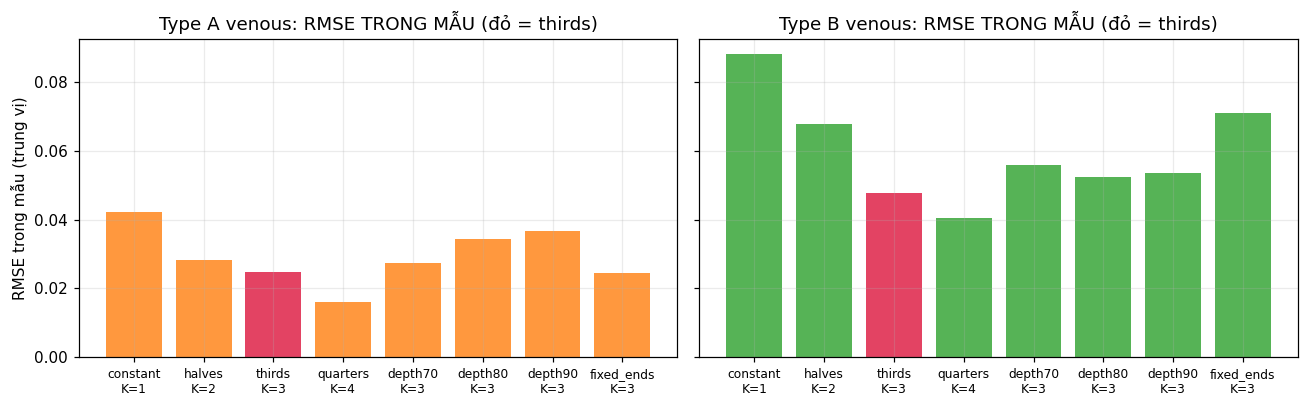

In [20]:
_SYS = {}
def get_sys(sc, did, r):
    key = (sc, did, round(float(r), 8))
    if key not in _SYS:
        s = SER[did]; B, b0, K = design(D.at[did, "Td"], s["t_min"].values, BOUNDS[(sc, did)], r); _SYS[key] = (B, b0, s["Hb"].values, K)
    return _SYS[key]

def aicc(sse, n, k): n = max(n, k + 2); return n * np.log(max(sse, 1e-12) / n) + 2 * k + 2 * k * (k + 1) / max(n - k - 1, 1)
def aicc_eff(sse, n, k, neff): neff = float(np.clip(neff, k + 2, n)); return neff * np.log(max(sse, 1e-12) / n) + 2 * k + 2 * k * (k + 1) / max(neff - k - 1, 1)
def lag1(res):
    r_ = np.asarray(res, float) - np.mean(res); den = np.sum(r_ * r_)
    return float(np.sum(r_[:-1] * r_[1:]) / den) if (len(r_) >= 8 and den > 0) else np.nan

rows, THETA = [], {}
for sc in SCHEMES:
    for did in D.index:
        B, b0, y, K = get_sys(sc, did, R); th = fit_ls(B, b0, y); e = y - b0 - B @ th; n = len(y); sse = float(e @ e)
        rho = lag1(e); neff = n * (1 - np.clip(rho, 0, 0.95)) / (1 + np.clip(rho, 0, 0.95)) if np.isfinite(rho) else n
        THETA[(sc, did)] = th
        rows.append({"scheme": sc, "dive_id": did, "group": D.at[did, "group"], "bird": D.at[did, "bird"], "K": K, "n": n, "sse": sse,
                     "rmse_in": np.sqrt(sse / n), "r2_in": 1 - sse / np.sum((y - y.mean()) ** 2), "rho1": rho, "n_eff": neff,
                     "aicc": aicc(sse, n, K + 1), "aicc_eff": aicc_eff(sse, n, K + 1, neff)})
FIT = pd.DataFrame(rows)
order = list(SCHEMES)
INS = FIT.groupby(["group", "scheme"]).agg(K=("K", "first"), rmse_trong_mau=("rmse_in", "median"), r2_trong_mau=("r2_in", "median"),
                                           rho1=("rho1", "median"), aicc_tong=("aicc", "sum"), aicc_eff_tong=("aicc_eff", "sum")).reset_index()
INS["scheme"] = pd.Categorical(INS["scheme"], order, ordered=True); INS = INS.sort_values(["group", "scheme"])
for c in ("aicc_tong", "aicc_eff_tong"):
    INS["d_" + c] = INS[c] - INS.groupby("group")[c].transform(lambda s: s[INS.loc[s.index, "scheme"] == MAIN].iloc[0])
print("TRONG MẪU (trung vị theo cú lặn; d_aicc = tổng AICc − tổng AICc của 'thirds', âm = tốt hơn 'thirds'):")
display(INS.set_index(["group", "scheme"]).round(3))
INS.to_csv(f"{RES_DIR}/phase_split_in_sample.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a_, grp in zip(ax, GROUPS):
    s = INS[INS["group"] == grp]; a_.bar(range(len(s)), s["rmse_trong_mau"], color=[("crimson" if x == MAIN else COL[grp]) for x in s["scheme"]], alpha=0.8)
    a_.set_xticks(range(len(s))); a_.set_xticklabels([f"{x}\nK={k}" for x, k in zip(s["scheme"], s["K"])], fontsize=8); a_.set_title(f"{grp}: RMSE TRONG MẪU (đỏ = thirds)")
ax[0].set_ylabel("RMSE trong mẫu (trung vị)"); plt.tight_layout(); plt.show()

## 6. Ngoài mẫu (leave-one-bird-out) cho mọi cách chia

Bước này đo **khả năng dự báo** của từng cách chia trên chim chưa từng thấy, cùng quy trình với mục 8e của notebook chính:
1. $g_1,\dots,g_K$ chung theo nhóm, ước lượng từ các chim khác (mỗi cú lặn huấn luyện có $S_{init}$ riêng);
2. $r$ lồng nhau (`R_NESTED`), không dùng chim bị bỏ;
3. $S_{init}$ của cú lặn bị bỏ lấy từ $S_v$ trước lặn;
4. đường chuẩn: giữ nguyên $S_{init}$.

Mốc theo độ sâu được tính từ độ sâu của **chính cú lặn bị bỏ** (độ sâu là biến ngoại sinh, biết trước, không lộ $S_v$ cần dự báo), còn $g_k$ lấy từ chim khác. Mọi cách chia được so trên **cùng các cú lặn** (cú lặn có $S_v$ trước lặn).

So sánh cặp với `thirds`: $\Delta_d=\mathrm{RMSE}_{ngoài\ mẫu}(\text{cách chia})-\mathrm{RMSE}_{ngoài\ mẫu}(\text{thirds})$ trên từng cú lặn; khoảng tin cậy 95% cho trung bình $\Delta$ bằng bootstrap theo cá thể. Khoảng chứa 0 nghĩa là chưa phân biệt được với `thirds`.

Số cú lặn đánh giá ngoài mẫu (chung cho mọi cách chia): 68 từ 10 chim
NGOÀI MẪU (leave-one-bird-out; delta = RMSE ngoài mẫu của cách chia − của 'thirds', trung bình theo cú lặn):


K  rmse_ngoai_mau_trung_vi  \
group         scheme                                   
Type A venous constant    1                    0.173   
              halves      2                    0.148   
              thirds      3                    0.144   
              quarters    4                    0.144   
              depth70     3                    0.139   
              depth80     3                    0.168   
              depth90     3                    0.154   
              fixed_ends  3                    0.148   
Type B venous constant    1                    0.260   
              halves      2                    0.263   
              thirds      3                    0.265   
              quarters    4                    0.263   
              depth70     3                    0.271   
              depth80     3                    0.265   
              depth90     3                    0.255   
              fixed_ends  3                    0.264   

                          rmse_duong_chuan_trung_vi  skill_trung_vi  \
group         scheme                                                  
Type A venous constant                        0.125          -0.886   
              halves                          0.125          -0.927   
              thirds                          0.125          -0.899   
              quarters                        0.125          -0.907   
              depth70                         0.125          -0.307   
              depth80                         0.125          -0.789   
              depth90                         0.125          -1.149   
              fixed_ends                      0.125          -0.611   
Type B venous constant                        0.277           0.336   
              halves                          0.277           0.375   
              thirds                          0.277           0.378   
              quarters                        0.277           0.386   
              depth70                         0.277           0.401   
              depth80                         0.277           0.406   
              depth90                         0.277           0.315   
              fixed_ends                      0.277           0.382   

                          ti_le_thang_duong_chuan  delta_so_voi_thirds  \
group         scheme                                                     
Type A venous constant                      0.333                0.006   
              halves                        0.333                0.001   
              thirds                        0.389                0.000   
              quarters                      0.389               -0.000   
              depth70                       0.500               -0.012   
              depth80                       0.500               -0.004   
              depth90                       0.444                0.002   
              fixed_ends                    0.333               -0.000   
Type B venous constant                      0.640               -0.004   
              halves                        0.640                0.000   
              thirds                        0.640                0.000   
              quarters                      0.620               -0.000   
              depth70                       0.580                0.003   
              depth80                       0.600                0.002   
              depth90                       0.620                0.001   
              fixed_ends                    0.640               -0.000   

                          KTC95_theo_chim_lo  KTC95_theo_chim_hi  \
group         scheme                                               
Type A venous constant                -0.008               0.019   
              halves                  -0.003               0.003   
              thirds                   0.000               0.000   
              quarters                -0.001               0.000 

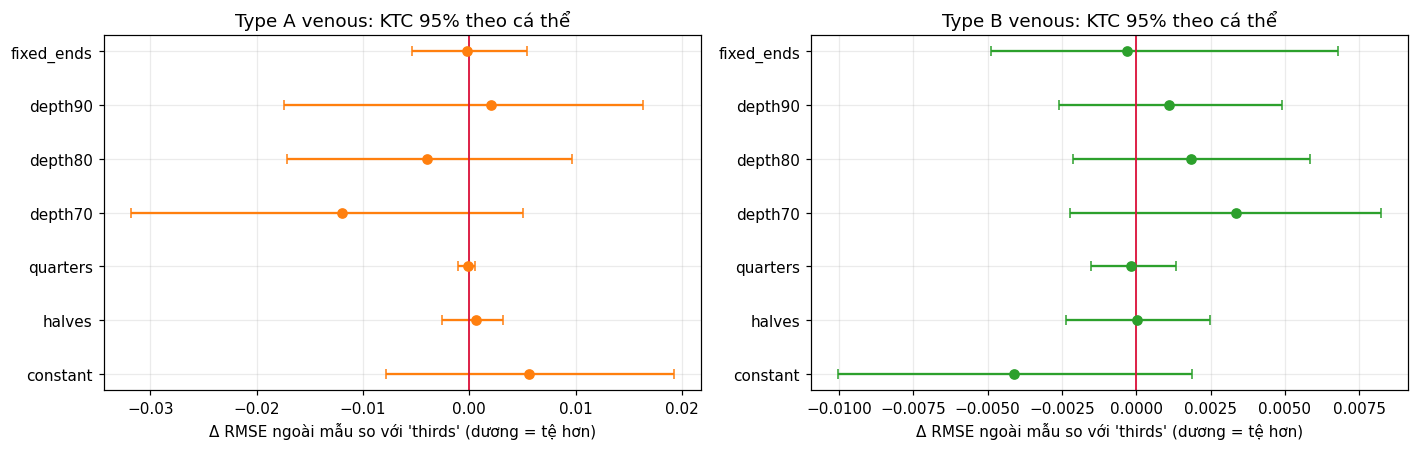

In [21]:
def pooled_g(sc, ids, r):
    K = get_sys(sc, ids[0], r)[3]; blocks, ys = [], []
    for i, did in enumerate(ids):
        B, b0, y, _ = get_sys(sc, did, r); Z = np.zeros((len(y), len(ids) + K)); Z[:, i] = B[:, 0]; Z[:, len(ids):] = B[:, 1:]; blocks.append(Z); ys.append(y - b0)
    lo = np.zeros(len(ids) + K); hi = np.r_[np.ones(len(ids)), np.full(K, G_MAX)]
    return lsq_linear(np.vstack(blocks), np.concatenate(ys), bounds=(lo, hi)).x[-K:]

def lobo_scheme(sc):
    rows = []
    for grp in GROUPS:
        ids_grp = list(D.index[D["group"] == grp])
        for bird in sorted(D.loc[ids_grp, "bird"].unique()):
            test = [i for i in ids_grp if D.at[i, "bird"] == bird and np.isfinite(D.at[i, "S_pre"])]
            train = [i for i in ids_grp if D.at[i, "bird"] != bird]
            if not test or len(train) < 5: continue
            r_ = R_NESTED.get(bird, R); gh = pooled_g(sc, train, r_)
            for did in test:
                B, b0, y, K = get_sys(sc, did, r_); S0 = D.at[did, "S_pre"]
                rows.append({"scheme": sc, "dive_id": did, "group": grp, "bird": bird, "n": len(y), "sse": float(np.sum((y - (B @ np.r_[S0, gh] + b0)) ** 2)),
                             "sse_naive": float(np.sum((y - S0) ** 2))})
    return pd.DataFrame(rows)

OOS = pd.concat([lobo_scheme(sc) for sc in SCHEMES], ignore_index=True)
OOS["rmse_out"] = np.sqrt(OOS["sse"] / OOS["n"]); OOS["rmse_naive"] = np.sqrt(OOS["sse_naive"] / OOS["n"]); OOS["skill"] = 1 - OOS["sse"] / OOS["sse_naive"]
common = OOS.groupby("dive_id")["scheme"].nunique(); OOS = OOS[OOS["dive_id"].isin(common[common == len(SCHEMES)].index)]
print(f"Số cú lặn đánh giá ngoài mẫu (chung cho mọi cách chia): {OOS['dive_id'].nunique()} từ {OOS['bird'].nunique()} chim")

def cluster_boot_mean(df, col, B=N_BOOT_BIRD, seed=SEED):
    rng = np.random.default_rng(seed); byb = {b: s[col].values for b, s in df.groupby("bird")}; birds = np.array(list(byb)); out = np.empty(B)
    for i in range(B):
        sb = rng.choice(birds, len(birds), replace=True)
        out[i] = np.mean(np.concatenate([rng.choice(byb[b], len(byb[b]), replace=True) for b in sb]))
    return np.percentile(out, [2.5, 97.5])

piv = OOS.pivot_table(index=["dive_id", "group", "bird"], columns="scheme", values="rmse_out").reset_index()
rows = []
for grp in GROUPS:
    pg = piv[piv["group"] == grp]; ng = OOS[(OOS["group"] == grp) & (OOS["scheme"] == MAIN)]
    for sc in SCHEMES:
        d_ = (pg[sc] - pg[MAIN]).rename("delta"); tmp = pd.DataFrame({"bird": pg["bird"].values, "delta": d_.values})
        ci = cluster_boot_mean(tmp, "delta") if sc != MAIN else (0.0, 0.0)
        o = OOS[(OOS["group"] == grp) & (OOS["scheme"] == sc)]
        rows.append({"group": grp, "scheme": sc, "K": get_sys(sc, o["dive_id"].iloc[0], R)[3], "rmse_ngoai_mau_trung_vi": o["rmse_out"].median(),
                     "rmse_duong_chuan_trung_vi": o["rmse_naive"].median(), "skill_trung_vi": o["skill"].median(), "ti_le_thang_duong_chuan": (o["rmse_out"] < o["rmse_naive"]).mean(),
                     "delta_so_voi_thirds": d_.mean(), "KTC95_theo_chim_lo": ci[0], "KTC95_theo_chim_hi": ci[1],
                     "chua_phan_biet_voi_thirds": (ci[0] <= 0 <= ci[1]) if sc != MAIN else np.nan})
OOSS = pd.DataFrame(rows)
print("NGOÀI MẪU (leave-one-bird-out; delta = RMSE ngoài mẫu của cách chia − của 'thirds', trung bình theo cú lặn):")
display(OOSS.set_index(["group", "scheme"]).round(3)); OOSS.to_csv(f"{RES_DIR}/phase_split_out_of_sample.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a_, grp in zip(ax, GROUPS):
    s = OOSS[(OOSS["group"] == grp) & (OOSS["scheme"] != MAIN)].reset_index(drop=True)
    a_.errorbar(s["delta_so_voi_thirds"], range(len(s)), xerr=[s["delta_so_voi_thirds"] - s["KTC95_theo_chim_lo"], s["KTC95_theo_chim_hi"] - s["delta_so_voi_thirds"]], fmt="o", color=COL[grp], capsize=3)
    a_.axvline(0, color="crimson", lw=1.2); a_.set_yticks(range(len(s))); a_.set_yticklabels(s["scheme"]); a_.set_xlabel("Δ RMSE ngoài mẫu so với 'thirds' (dương = tệ hơn)")
    a_.set_title(f"{grp}: KTC 95% theo cá thể")
plt.tight_layout(); plt.savefig(f"{RES_DIR}/fig_phase_split_out_of_sample.png", dpi=140); plt.show()

## 7. Kết luận A vs B có phụ thuộc cách chia pha không?

$g_k$ của các cách chia khác nhau không so trực tiếp được (số đoạn khác nhau). Bước này dùng một đại lượng **không phụ thuộc cách chia**: $g$ trung bình theo thời gian của cú lặn, $\bar g=\sum_k g_k\,\ell_k/T_d$ ($\ell_k$ là độ dài đoạn $k$). Với từng cách chia, bảng cho: trung vị $\bar g$ theo nhóm, hiệu B − A kèm khoảng tin cậy 95% bootstrap theo cá thể (lấy mẫu chim chung cho hai nhóm), và hai kiểm định ở mức chim (Wilcoxon trên trung vị theo chim; hoán vị nhãn A/B trong từng chim). Chỉ 3 chim có cả hai loại lặn, nên Wilcoxon không thể có $p<0{,}25$; hoán vị trong chim chỉ cho kết luận về cú lặn của chính các chim đó.

g trung bình theo thời gian (g_bar) theo cách chia; KTC theo cá thể:


,K,gbar_A,gbar_B,B_tru_A,KTC95_lo,KTC95_hi,KTC_loai_tru_0,B_hon_A_o_so_chim,p_Wilcoxon_chim,p_hoan_vi_trong_chim,av_B_tru_A_mLdL
scheme,,,,,,,,,,,
constant,1,0.0852,0.4391,0.3539,0.0953,0.5803,True,3/3,0.25,0.0044,8.5370
halves,2,0.0854,0.4390,0.3536,0.0842,0.5750,True,3/3,0.25,0.0050,8.5291
thirds,3,0.0931,0.4284,0.3353,0.0689,0.5755,True,3/3,0.25,0.0085,8.0877
quarters,4,0.0968,0.4136,0.3168,0.0647,0.5752,True,3/3,0.25,0.0071,7.6407
depth70,3,0.0958,0.4232,0.3275,0.0797,0.5721,True,3/3,0.25,0.0069,7.8989
depth80,3,0.0866,0.4325,0.3460,0.0829,0.5703,True,3/3,0.25,0.0064,8.3448
depth90,3,0.0862,0.4374,0.3513,0.0839,0.5708,True,3/3,0.25,0.0062,8.4730
fixed_ends,3,0.0967,0.4079,0.3112,0.0610,0.5812,True,3/3,0.25,0.0073,7.5064


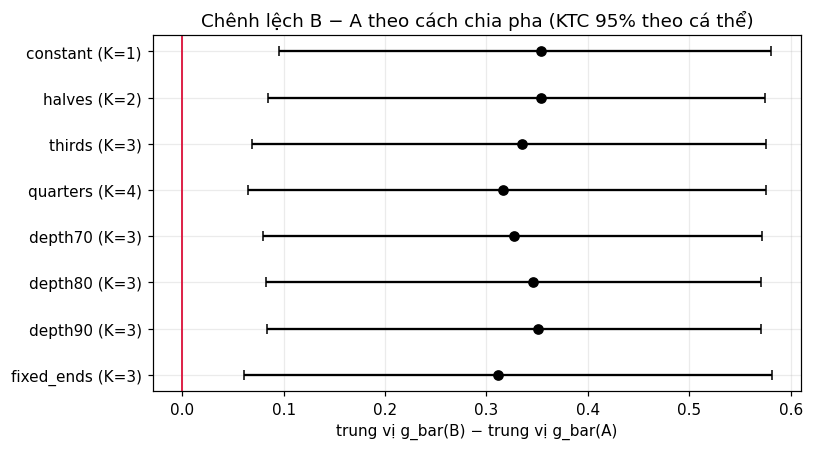

In [22]:
def mean_g(sc, did):
    Td = D.at[did, "Td"]; edges = np.r_[0.0, BOUNDS[(sc, did)], Td]; th = THETA[(sc, did)][1:]
    return float(np.sum(th * np.diff(edges)) / Td)
GB = pd.DataFrame([{"scheme": sc, "dive_id": did, "group": D.at[did, "group"], "bird": D.at[did, "bird"], "gbar": mean_g(sc, did)} for sc in SCHEMES for did in D.index])

def boot_diff(df, B=N_BOOT_BIRD, seed=SEED):
    # trung vị(B) − trung vị(A); lấy mẫu chim (chung cho hai nhóm) rồi lấy mẫu cú lặn trong chim
    rng = np.random.default_rng(seed); byb = {b: (s["group"].values, s["gbar"].values) for b, s in df.groupby("bird")}; birds = np.array(list(byb)); out = []
    for _ in range(B):
        g_, v_ = [], []
        for b in rng.choice(birds, len(birds), replace=True):
            gg, vv = byb[b]; k = rng.integers(0, len(vv), len(vv)); g_.append(gg[k]); v_.append(vv[k])
        g_, v_ = np.concatenate(g_), np.concatenate(v_)
        if (g_ == GROUPS[0]).any() and (g_ == GROUPS[1]).any(): out.append(np.median(v_[g_ == GROUPS[1]]) - np.median(v_[g_ == GROUPS[0]]))
    return np.percentile(out, [2.5, 97.5])

def perm_within_bird(df, n_perm=N_PERM, seed=SEED):
    rng = np.random.default_rng(seed)
    data = {b: (s["gbar"].values, (s["group"] == GROUPS[1]).values) for b, s in df.groupby("bird") if s["group"].nunique() == 2}
    stat = lambda lab: np.mean([np.median(v[lab[b]]) - np.median(v[~lab[b]]) for b, (v, _) in data.items()])
    obs = stat({b: l for b, (v, l) in data.items()}); cnt = sum(abs(stat({b: rng.permutation(l) for b, (v, l) in data.items()})) >= abs(obs) - 1e-12 for _ in range(n_perm))
    return obs, (cnt + 1) / (n_perm + 1), len(data)

rows = []
for sc in SCHEMES:
    d_ = GB[GB["scheme"] == sc]; a_ = d_[d_["group"] == GROUPS[0]]["gbar"]; b_ = d_[d_["group"] == GROUPS[1]]["gbar"]
    lo, hi = boot_diff(d_); bm = d_.groupby(["bird", "group"])["gbar"].median().unstack().dropna(); diff = bm[GROUPS[1]] - bm[GROUPS[0]]
    obs, pp, nb = perm_within_bird(d_)
    rows.append({"scheme": sc, "K": SCHEMES[sc][1].__len__(), "gbar_A": a_.median(), "gbar_B": b_.median(), "B_tru_A": b_.median() - a_.median(),
                 "KTC95_lo": lo, "KTC95_hi": hi, "KTC_loai_tru_0": bool(lo > 0 or hi < 0), "B_hon_A_o_so_chim": f"{int((diff > 0).sum())}/{len(diff)}",
                 "p_Wilcoxon_chim": wilcoxon(diff).pvalue if len(diff) >= 3 and (diff != 0).any() else np.nan, "p_hoan_vi_trong_chim": pp,
                 "av_B_tru_A_mLdL": (b_.median() - a_.median()) * AV_FACTOR})
ROB = pd.DataFrame(rows).set_index("scheme")
print("g trung bình theo thời gian (g_bar) theo cách chia; KTC theo cá thể:"); display(ROB.round(4)); ROB.reset_index().to_csv(f"{RES_DIR}/phase_split_A_vs_B_robustness.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.2)); r_ = ROB.reset_index()
ax.errorbar(r_["B_tru_A"], range(len(r_)), xerr=[r_["B_tru_A"] - r_["KTC95_lo"], r_["KTC95_hi"] - r_["B_tru_A"]], fmt="o", color="k", capsize=3)
ax.axvline(0, color="crimson", lw=1.2); ax.set_yticks(range(len(r_))); ax.set_yticklabels([f"{s} (K={k})" for s, k in zip(r_["scheme"], r_["K"])]); ax.invert_yaxis()
ax.set(xlabel="trung vị g_bar(B) − trung vị g_bar(A)", title="Chênh lệch B − A theo cách chia pha (KTC 95% theo cá thể)")
plt.tight_layout(); plt.savefig(f"{RES_DIR}/fig_phase_split_A_vs_B.png", dpi=140); plt.show()

### 7.1 Hướng chênh lệch theo từng đoạn

Bước này liệt kê trung vị $g_k$ của từng nhóm trong **từng đoạn** của mỗi cách chia và dấu của chênh lệch B − A, để kiểm tra Type B có $g$ lớn hơn Type A ở mọi đoạn hay chỉ ở một số đoạn.

In [23]:
rows = []
for sc, (fn, labs) in SCHEMES.items():
    for k, lab in enumerate(labs):
        v = {grp: np.array([THETA[(sc, did)][1 + k] for did in D.index[D["group"] == grp]]) for grp in GROUPS}
        rows.append({"scheme": sc, "doan": lab, "g_A": np.median(v[GROUPS[0]]), "g_B": np.median(v[GROUPS[1]]), "B_tru_A": np.median(v[GROUPS[1]]) - np.median(v[GROUPS[0]])})
SEGT = pd.DataFrame(rows); SEGT["B_lon_hon_A"] = SEGT["B_tru_A"] > 0
display(SEGT.set_index(["scheme", "doan"]).round(3)); SEGT.to_csv(f"{RES_DIR}/phase_split_g_by_segment.csv", index=False)
print("Tỉ lệ đoạn (qua mọi cách chia) có trung vị g của B lớn hơn A:", f"{int(SEGT['B_lon_hon_A'].sum())}/{len(SEGT)}")

g_A    g_B  B_tru_A  B_lon_hon_A
scheme     doan                                              
constant   cả cú lặn       0.085  0.439    0.354         True
halves     nửa đầu         0.007  0.396    0.389         True
           nửa sau         0.117  0.460    0.343         True
thirds     đầu (0–1/3)     0.000  0.380    0.380         True
           giữa (1/3–2/3)  0.054  0.483    0.429         True
           cuối (2/3–1)    0.146  0.422    0.276         True
quarters   Q1              0.000  0.361    0.361         True
           Q2              0.005  0.495    0.489         True
           Q3              0.072  0.444    0.371         True
           Q4              0.153  0.453    0.299         True
depth70    xuống           0.000  0.346    0.346         True
           đáy             0.000  0.435    0.435         True
           lên             0.143  0.453    0.310         True
depth80    xuống           0.000  0.359    0.359         True
           đáy             0.000  0.491    0.491         True
           lên             0.116  0.428    0.312         True
depth90    xuống           0.001  0.375    0.374         True
           đáy             0.000  0.557    0.557         True
           lên             0.120  0.436    0.316         True
fixed_ends 1 phút đầu      0.000  0.311    0.311         True
           giữa            0.064  0.447    0.383         True
           1 phút cuối     0.200  0.659    0.459         True

Tỉ lệ đoạn (qua mọi cách chia) có trung vị g của B lớn hơn A: 22/22


## 8. Tên gọi theo sinh lý: $g$ theo cách chia độ sâu (cách phụ)

$g_1,g_2,g_3$ của `thirds` là "đoạn đầu / giữa / cuối của cú lặn", **không phải** pha xuống / đáy / lên (mục 3.1). Nếu báo cáo cần nhãn sinh lý thì dùng `depth80` và nêu rõ đây là cách phụ. Bước này tính trung vị $g$ theo pha độ sâu cho mỗi nhóm, kèm khoảng tin cậy theo cá thể và quy đổi sang hiệu số a-v (mL O₂/dL = $g\times$ 24,12). Lưu ý: "đáy" tính từ lần đầu đến lần cuối độ sâu $\ge 80\%\ z_{max}$ nên chứa cả các lần trồi/lặn trung gian của cú lặn Type B.

In [24]:
def cluster_boot_median(df, col, B=N_BOOT_BIRD, seed=SEED):
    rng = np.random.default_rng(seed); byb = {b: s[col].values for b, s in df.groupby("bird")}; birds = np.array(list(byb)); out = np.empty(B)
    for i in range(B):
        sb = rng.choice(birds, len(birds), replace=True)
        out[i] = np.median(np.concatenate([rng.choice(byb[b], len(byb[b]), replace=True) for b in sb]))
    return np.percentile(out, [2.5, 97.5])

rows = []
for grp in GROUPS:
    ids = [i for i in D.index[D["group"] == grp] if not FALLBACK[("depth80", i)]]
    for k, lab in enumerate(SCHEMES["depth80"][1]):
        df = pd.DataFrame({"bird": [D.at[i, "bird"] for i in ids], "g": [THETA[("depth80", i)][1 + k] for i in ids]}); ci = cluster_boot_median(df, "g")
        rows.append({"nhóm": grp, "pha": lab, "n": len(ids), "g_trung_vi": df["g"].median(), "KTC95_theo_chim": f"{ci[0]:.3f}–{ci[1]:.3f}",
                     "a-v (mL O2/dL)": df["g"].median() * AV_FACTOR, "KTC95_a-v": f"{ci[0]*AV_FACTOR:.1f}–{ci[1]*AV_FACTOR:.1f}"})
PHYS = pd.DataFrame(rows); display(PHYS.round(3)); PHYS.to_csv(f"{RES_DIR}/g_by_depth_phase.csv", index=False)

,nhóm,pha,n,g_trung_vi,KTC95_theo_chim,a-v (mL O2/dL),KTC95_a-v
0,Type A venous,xuống,18,0.000,0.000–0.060,0.000,0.0–1.4
1,Type A venous,đáy,18,0.000,0.000–0.128,0.000,0.0–3.1
2,Type A venous,lên,18,0.116,0.000–0.312,2.800,0.0–7.5
3,Type B venous,xuống,61,0.359,0.079–0.615,8.665,1.9–14.8
4,Type B venous,đáy,61,0.491,0.292–0.674,11.832,7.0–16.2
5,Type B venous,lên,61,0.428,0.169–0.655,10.335,4.1–15.8


## 9. Quy tắc chọn cách chia và tóm tắt tự động

Quy tắc đề xuất, theo thứ tự ưu tiên:
1. **Chọn theo lý do có sẵn trước khi nhìn dữ liệu:** cách chia của ghi chú (`thirds`), đơn giản, không phụ thuộc ngưỡng độ sâu.
2. **Không chọn bằng sai số trong mẫu.** Làm vậy là chọn mô hình trên chính dữ liệu dùng để báo cáo, và luôn ưu ái cách chia nhiều đoạn.
3. **Chỉ đổi cách chia nếu cách khác tốt hơn rõ rệt ngoài mẫu**, tức khoảng tin cậy theo cá thể của $\Delta$ RMSE ngoài mẫu không chứa 0.
4. Các cách chia còn lại trình bày như **phân tích độ nhạy**; nhãn sinh lý chỉ gắn cho cách chia theo độ sâu.

Ô dưới tự tính các mệnh đề này từ kết quả ở trên.

In [25]:
print("=== TÓM TẮT TỰ ĐỘNG ===\n")
for grp in GROUPS:
    s_in = INS[INS["group"] == grp]; k3 = s_in[s_in["K"] == 3]
    best_all = s_in.loc[s_in["rmse_trong_mau"].idxmin(), "scheme"]; best_k3 = k3.loc[k3["rmse_trong_mau"].idxmin(), "scheme"]
    print(f"[{grp}] RMSE TRONG MẪU nhỏ nhất: {best_all} (mọi K); {best_k3} (trong các cách chia 3 đoạn).")
    o = OOSS[(OOSS["group"] == grp) & (OOSS["scheme"] != MAIN)]
    better = o[(o["KTC95_theo_chim_hi"] < 0)]["scheme"].tolist(); worse = o[(o["KTC95_theo_chim_lo"] > 0)]["scheme"].tolist()
    print(f"   NGOÀI MẪU so với thirds: tốt hơn rõ rệt = {better or 'không cách nào'}; tệ hơn rõ rệt = {worse or 'không cách nào'}; "
          f"chưa phân biệt = {o[o['chua_phan_biet_voi_thirds'] == True]['scheme'].tolist()}")
    t = OOSS[(OOSS["group"] == grp) & (OOSS["scheme"] == MAIN)].iloc[0]
    print(f"   thirds: RMSE ngoài mẫu trung vị {t['rmse_ngoai_mau_trung_vi']:.3f} so với đường chuẩn {t['rmse_duong_chuan_trung_vi']:.3f}; thắng đường chuẩn ở {100*t['ti_le_thang_duong_chuan']:.0f}% cú lặn.\n")
n_pos = int((ROB["B_tru_A"] > 0).sum()); n_ci = int(ROB["KTC_loai_tru_0"].sum())
print(f"A vs B: g_bar của Type B lớn hơn Type A ở {n_pos}/{len(ROB)} cách chia; khoảng tin cậy 95% theo cá thể loại trừ 0 ở {n_ci}/{len(ROB)} cách chia.")
print(f"        chênh lệch B − A (trung vị g_bar) nằm trong khoảng {ROB['B_tru_A'].min():.3f} đến {ROB['B_tru_A'].max():.3f}  (= {ROB['av_B_tru_A_mLdL'].min():.1f} đến {ROB['av_B_tru_A_mLdL'].max():.1f} mL O2/dL).")
print(f"        trung vị g của B lớn hơn A ở {int(SEGT['B_lon_hon_A'].sum())}/{len(SEGT)} đoạn (qua mọi cách chia).")

=== TÓM TẮT TỰ ĐỘNG ===

[Type A venous] RMSE TRONG MẪU nhỏ nhất: quarters (mọi K); fixed_ends (trong các cách chia 3 đoạn).
   NGOÀI MẪU so với thirds: tốt hơn rõ rệt = không cách nào; tệ hơn rõ rệt = không cách nào; chưa phân biệt = ['constant', 'halves', 'quarters', 'depth70', 'depth80', 'depth90', 'fixed_ends']
   thirds: RMSE ngoài mẫu trung vị 0.144 so với đường chuẩn 0.125; thắng đường chuẩn ở 39% cú lặn.

[Type B venous] RMSE TRONG MẪU nhỏ nhất: quarters (mọi K); thirds (trong các cách chia 3 đoạn).
   NGOÀI MẪU so với thirds: tốt hơn rõ rệt = không cách nào; tệ hơn rõ rệt = không cách nào; chưa phân biệt = ['constant', 'halves', 'quarters', 'depth70', 'depth80', 'depth90', 'fixed_ends']
   thirds: RMSE ngoài mẫu trung vị 0.265 so với đường chuẩn 0.277; thắng đường chuẩn ở 64% cú lặn.

A vs B: g_bar của Type B lớn hơn Type A ở 8/8 cách chia; khoảng tin cậy 95% theo cá thể loại trừ 0 ở 8/8 cách chia.
        chênh lệch B − A (trung vị g_bar) nằm trong khoảng 0.311 đến 0.354  (= 

### Cách đưa vào báo cáo

- Nêu cách chia $1/3$–$2/3$ là cách chính và lý do chọn (theo ghi chú, tiết kiệm tham số, không phụ thuộc ngưỡng).
- Gọi $g_1,g_2,g_3$ là **đoạn đầu / giữa / cuối của cú lặn**; chỉ dùng "xuống / đáy / lên" cho kết quả của cách chia theo độ sâu (mục 8).
- Dùng bảng mục 7 để nói kết luận A vs B có bền với cách chia hay không, kèm hạn chế: số chim có cả hai loại lặn rất ít.
- Dùng bảng mục 6 để nói rõ không cách chia nào dự báo tốt hơn rõ rệt ngoài mẫu (hoặc cách nào, nếu kết quả tự động nêu).

## 10. Xuất kết quả

In [26]:
D.reset_index().to_csv(f"{RES_DIR}/phase_split_dive_set.csv", index=False)
FIT.drop(columns=[]).to_csv(f"{RES_DIR}/phase_split_fits_per_dive.csv", index=False)
OOS.to_csv(f"{RES_DIR}/phase_split_oos_per_dive.csv", index=False)
print("Đã xuất vào", RES_DIR, ":", sorted(f for f in os.listdir(RES_DIR) if f.startswith(("phase_split", "g_by_depth", "fig_phase", "fig_thirds"))))

Đã xuất vào ../results/split_sensitivity : ['fig_phase_boundaries_examples.png', 'fig_phase_split_A_vs_B.png', 'fig_phase_split_out_of_sample.png', 'fig_thirds_vs_depth_phases.png', 'g_by_depth_phase.csv', 'phase_split_A_vs_B_robustness.csv', 'phase_split_dive_set.csv', 'phase_split_fits_per_dive.csv', 'phase_split_g_by_segment.csv', 'phase_split_in_sample.csv', 'phase_split_oos_per_dive.csv', 'phase_split_out_of_sample.csv']
